In [1]:
# Drive Mounting and GPU Verification

from google.colab import drive
from pathlib import Path
import sys
import torch
import pandas as pd

drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy"
)

OUTPUT_DIR = BASE / "outputs"
V2_DIR = OUTPUT_DIR / "v2"
MODEL_DIR = V2_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load Original Dataset Splits
train_df = pd.read_csv(OUTPUT_DIR / "dr_train.csv")
val_df = pd.read_csv(OUTPUT_DIR / "dr_val.csv")
test_df = pd.read_csv(OUTPUT_DIR / "dr_test.csv")

# Import V2 Preprocessing
sys.path.insert(0, str(V2_DIR))

from dr_preprocessing_v2 import preprocess_dr_v2

# GPU Verification
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset splits:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nPreprocessing module imported successfully.")
print("V2 model directory:", MODEL_DIR)


Mounted at /content/drive
Device: cuda
GPU: NVIDIA L4

Dataset splits:
Training: 2094
Validation: 445
Test: 460

Preprocessing module imported successfully.
V2 model directory: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/models


In [2]:

# DR V2 Dataset and DataLoaders

import random
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# Training-Only Augmentation
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Deterministic Validation Transform
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset
class DRDatasetV2(Dataset):

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = preprocess_dr_v2(row["image_path"])
        label = int(row["classe"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# Datasets
train_dataset = DRDatasetV2(train_df, train_transform)
val_dataset = DRDatasetV2(val_df, val_transform)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Verify Batch
images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label values:", sorted(set(labels.tolist())))
print("Device:", device)


Training images: 2094
Validation images: 445
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Label values: [0, 1, 2, 3, 4]
Device: cuda


In [3]:
# DenseNet-121 Model Initialization

import torch
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

# Load ImageNet Pretrained Model
cnn_weights = DenseNet121_Weights.DEFAULT
cnn_model = densenet121(weights=cnn_weights)

# Configure Five-Class Classification
num_features = cnn_model.classifier.in_features
cnn_model.classifier = nn.Linear(num_features, 5)

# Move Model to GPU
cnn_model = cnn_model.to(device)

# Verify Model
print("Model: DenseNet-121")
print("Output classes:", cnn_model.classifier.out_features)
print("Device:", next(cnn_model.parameters()).device)

total_params = sum(p.numel() for p in cnn_model.parameters())
trainable_params = sum(
    p.numel() for p in cnn_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 230MB/s]


Model: DenseNet-121
Output classes: 5
Device: cuda:0
Total parameters: 6,958,981
Trainable parameters: 6,958,981


In [4]:

# DenseNet-121 Training Configuration

import torch
import torch.nn as nn
import random
import numpy as np

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# Training Settings
cnn_epochs = 10
cnn_learning_rate = 1e-4

# Loss Function
cnn_criterion = nn.CrossEntropyLoss()

# Optimizer
cnn_optimizer = torch.optim.AdamW(
    cnn_model.parameters(),
    lr=cnn_learning_rate,
    weight_decay=1e-4
)

# Learning Rate Scheduler
cnn_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    cnn_optimizer,
    T_max=cnn_epochs
)

# Mixed Precision
use_amp = device.type == "cuda"

cnn_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

# Verify Configuration
print("Model: DenseNet-121")
print("Epochs:", cnn_epochs)
print("Learning rate:", cnn_learning_rate)
print("Optimizer: AdamW")
print("Weight decay:", 1e-4)
print("Batch size:", train_loader.batch_size)
print("Mixed precision:", use_amp)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))


Model: DenseNet-121
Epochs: 10
Learning rate: 0.0001
Optimizer: AdamW
Weight decay: 0.0001
Batch size: 16
Mixed precision: True
Training images: 2094
Validation images: 445


In [5]:
# DenseNet-121 V2 Training with Progress Bars

import torch
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

best_path = MODEL_DIR / "dr_v2_densenet121_best.pth"
resume_path = MODEL_DIR / "dr_v2_densenet121_resume.pth"
history_path = V2_DIR / "dr_v2_densenet121_training_history.csv"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_auc = -1.0
best_epoch = 0
start_epoch = 1
patience = 3
epochs_without_improvement = 0
history = []

# Resume Previous Training
if resume_path.exists():
    checkpoint = torch.load(
        resume_path,
        map_location=device,
        weights_only=False
    )

    cnn_model.load_state_dict(checkpoint["model"])
    cnn_optimizer.load_state_dict(checkpoint["optimizer"])
    cnn_scheduler.load_state_dict(checkpoint["scheduler"])
    cnn_scaler.load_state_dict(checkpoint["scaler"])

    start_epoch = checkpoint["epoch"] + 1
    best_auc = checkpoint["best_auc"]
    best_epoch = checkpoint["best_epoch"]
    epochs_without_improvement = checkpoint["no_improve"]
    history = checkpoint["history"]

    print(f"Resuming from epoch {start_epoch}")

else:
    print("Starting new training run")

for epoch in range(start_epoch, cnn_epochs + 1):

    # Training
    cnn_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{cnn_epochs} - Train",
        leave=False
    )

    for images, labels in train_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        cnn_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            outputs = cnn_model(images)
            loss = cnn_criterion(outputs, labels)

        cnn_scaler.scale(loss).backward()
        cnn_scaler.step(cnn_optimizer)
        cnn_scaler.update()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{train_loss_sum / train_total:.3f}",
            acc=f"{train_correct / train_total:.3f}"
        )

    # Validation
    cnn_model.eval()
    val_labels = []
    val_probs = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch}/{cnn_epochs} - Val",
        leave=False
    )

    with torch.inference_mode():
        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = cnn_model(images)

            probs = torch.softmax(outputs.float(), dim=1)

            val_labels.append(labels.numpy())
            val_probs.append(probs.cpu().numpy())

    val_labels = np.concatenate(val_labels)
    val_probs = np.concatenate(val_probs)

    val_acc = (
        val_probs.argmax(axis=1) == val_labels
    ).mean()

    val_auc = roc_auc_score(
        val_labels,
        val_probs,
        multi_class="ovr",
        average="macro",
        labels=[0, 1, 2, 3, 4]
    )

    # Save Best Model
    if val_auc > best_auc:
        best_auc = val_auc
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(cnn_model.state_dict(), best_path)
        print(f"Best model saved at epoch {epoch}")

    else:
        epochs_without_improvement += 1

    # Save History
    history.append({
        "epoch": epoch,
        "train_loss": train_loss_sum / train_total,
        "train_accuracy": train_correct / train_total,
        "val_accuracy": val_acc,
        "val_macro_auc": val_auc
    })

    pd.DataFrame(history).to_csv(history_path, index=False)

    cnn_scheduler.step()

    # Save Resume Checkpoint
    torch.save({
        "epoch": epoch,
        "model": cnn_model.state_dict(),
        "optimizer": cnn_optimizer.state_dict(),
        "scheduler": cnn_scheduler.state_dict(),
        "scaler": cnn_scaler.state_dict(),
        "best_auc": best_auc,
        "best_epoch": best_epoch,
        "no_improve": epochs_without_improvement,
        "history": history
    }, resume_path)

    print(
        f"Epoch {epoch}/{cnn_epochs} | "
        f"Train Acc: {train_correct / train_total:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val AUROC: {val_auc:.4f} | "
        f"Best AUROC: {best_auc:.4f}"
    )

    # Early Stopping
    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation macro AUROC:", round(best_auc, 4))
print("Best checkpoint:", best_path)


Resuming from epoch 11

Training finished.
Best epoch: 7
Best validation macro AUROC: 0.886
Best checkpoint: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/models/dr_v2_densenet121_best.pth


In [6]:

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load the best checkpoint from this training run
checkpoint_path = (
    "/content/drive/MyDrive/Major_Project/"
    "Diabetic_Retinopathy/outputs/v2/models/"
    "dr_v2_densenet121_best.pth"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

cnn_model.load_state_dict(state_dict)
cnn_model = cnn_model.to(device)
cnn_model.eval()

# Validation predictions
y_true, y_probs = [], []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device)

        logits = cnn_model(images)
        probs = torch.softmax(logits.float(), dim=1)

        y_true.extend(labels.cpu().numpy())
        y_probs.extend(probs.cpu().numpy())

y_true = np.array(y_true, dtype=int)
y_probs = np.array(y_probs)
y_pred = np.argmax(y_probs, axis=1)

assert y_probs.shape == (445, 5), (
    f"Unexpected prediction shape: {y_probs.shape}"
)

# Metrics
y_onehot = np.eye(5)[y_true]

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Weighted Precision": precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "Weighted Recall": recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "Macro OvR AUROC": roc_auc_score(
        y_true,
        y_probs,
        multi_class="ovr",
        average="macro",
        labels=[0, 1, 2, 3, 4]
    ),
    "Multiclass Brier Score": np.mean(
        np.sum((y_probs - y_onehot) ** 2, axis=1)
    )
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"]
)

print("\nDR V2 DENSENET-121 — FINAL VALIDATION METRICS")
print("=" * 55)
print(f"Validation images: {len(y_true)}")
print(f"Correct predictions: {(y_true == y_pred).sum()}")
print("-" * 55)
print(
    metrics_df.to_string(
        index=False,
        formatters={"Value": "{:.6f}".format}
    )
)

print("\nPER-CLASS CLASSIFICATION REPORT")
print("=" * 55)
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        digits=4,
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")
print("=" * 55)
print(
    confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4]
    )
)



DR V2 DENSENET-121 — FINAL VALIDATION METRICS
Validation images: 445
Correct predictions: 264
-------------------------------------------------------
                Metric    Value
              Accuracy 0.593258
     Balanced Accuracy 0.604938
       Macro Precision 0.593805
          Macro Recall 0.604938
              Macro F1 0.597275
    Weighted Precision 0.590870
       Weighted Recall 0.593258
           Weighted F1 0.590010
       Macro OvR AUROC 0.885972
Multiclass Brier Score 0.530600

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.5000    0.5493    0.5235        71
           1     0.5288    0.5556    0.5419        99
           2     0.5341    0.4519    0.4896       104
           3     0.6705    0.6146    0.6413        96
           4     0.7356    0.8533    0.7901        75

    accuracy                         0.5933       445
   macro avg     0.5938    0.6049    0.5973       445
weighted avg     0.5909    0.5

In [7]:

# Find Existing DR V2 Model and Validation DataLoader

import torch
from torch.utils.data import DataLoader

print("AVAILABLE PYTORCH MODELS")
print("-" * 45)

models_found = []

for name, value in list(globals().items()):
    if isinstance(value, torch.nn.Module):
        models_found.append(name)
        print(f"{name}: {type(value).__name__}")

if not models_found:
    print("No model currently loaded in memory.")

print("\nAVAILABLE DATALOADERS")
print("-" * 45)

loaders_found = []

for name, value in list(globals().items()):
    if isinstance(value, DataLoader):
        loaders_found.append(name)
        print(f"{name}: {len(value.dataset)} images")

if not loaders_found:
    print("No DataLoader currently loaded in memory.")

print("\nDR V2 CHECKPOINT CANDIDATES")
print("-" * 45)

from pathlib import Path

drive_root = Path(
    "/content/drive/MyDrive/Major_Project"
)

if drive_root.exists():
    checkpoints = [
        p for p in drive_root.rglob("*.pth")
        if "retinopathy" in str(p).lower()
        or "/dr/" in str(p).lower()
    ]

    for path in checkpoints[:20]:
        print(path)

    if not checkpoints:
        print("No matching DR checkpoint paths found.")
else:
    print("Google Drive is not mounted.")


AVAILABLE PYTORCH MODELS
---------------------------------------------
cnn_model: DenseNet
cnn_criterion: CrossEntropyLoss

AVAILABLE DATALOADERS
---------------------------------------------
train_loader: 2094 images
val_loader: 445 images

DR V2 CHECKPOINT CANDIDATES
---------------------------------------------
/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/models/densenet121_best.pth
/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/models/dr_vit_b16_best.pth
/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/models/dr_v2_densenet121_best.pth
/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/models/dr_v2_densenet121_resume.pth


In [8]:

# ============================================================
# DR V2 — Vision Transformer (ViT-B/16)
# Five-class Diabetic Retinopathy Classification
# Research use only
# ============================================================

!pip -q install timm scikit-learn seaborn

import os
import json
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from google.colab import drive

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

drive.mount("/content/drive")

SEED = 42

DATA_ROOT = Path(
    "/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/data"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/vit_v2"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR = DATA_ROOT / "val"
TEST_DIR = DATA_ROOT / "test"

MODEL_NAME = "vit_base_patch16_224"
IMAGE_SIZE = 224

NUM_CLASSES = 5
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 5

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 3. IMAGE TRANSFORMS
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# 4. LOAD DATASETS
# ------------------------------------------------------------

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if not folder.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {folder}"
        )

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

if not (
    train_dataset.class_to_idx
    == val_dataset.class_to_idx
    == test_dataset.class_to_idx
):
    raise ValueError(
        "Class mappings differ between train, val, and test."
    )

expected_classes = {
    str(i): i for i in range(NUM_CLASSES)
}

if train_dataset.class_to_idx != expected_classes:
    raise ValueError(
        "Expected class folders 0, 1, 2, 3, 4. "
        f"Found: {train_dataset.class_to_idx}"
    )

print("Class mapping:", train_dataset.class_to_idx)
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

# ------------------------------------------------------------
# 5. DATA LOADERS
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 6. CLASS WEIGHTS — TRAINING DATA ONLY
# ------------------------------------------------------------

train_labels = np.array(
    train_dataset.targets,
    dtype=np.int64
)

class_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES
)

if np.any(class_counts == 0):
    raise ValueError(
        "Every DR class must be represented in training."
    )

class_weights = (
    len(train_labels)
    / (NUM_CLASSES * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("Training class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())

# ------------------------------------------------------------
# 7. CREATE PRETRAINED VISION TRANSFORMER
# ------------------------------------------------------------

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# ------------------------------------------------------------
# 8. TRAINING AND VALIDATION
# ------------------------------------------------------------

def run_epoch(loader, training=False):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )

    with context:
        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += (
                loss.item() * images.size(0)
            )

            predictions = logits.argmax(dim=1)

            all_labels.extend(
                labels.cpu().numpy().tolist()
            )

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_macro_f1
    )


history = []
best_val_f1 = -1.0
best_state = None
epochs_without_improvement = 0

CHECKPOINT_PATH = OUTPUT_DIR / "dr_vit_v2_best.pth"

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc, val_f1 = run_epoch(
        val_loader,
        training=False
    )

    scheduler.step()

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss={train_loss:.4f} | "
        f"Train F1={train_f1:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Val F1={val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_state,
            CHECKPOINT_PATH
        )

        epochs_without_improvement = 0

        print("  Saved new best checkpoint.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# ------------------------------------------------------------
# 9. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "dr_vit_v2_training_history.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation"
)

axes[1].set_title("Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "dr_vit_v2_training_curves.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# 10. LOAD BEST VALIDATION CHECKPOINT
# ------------------------------------------------------------

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

# ------------------------------------------------------------
# 11. FINAL HELD-OUT TEST EVALUATION
# ------------------------------------------------------------

y_true = []
y_pred = []
y_prob = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        logits = model(images)

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        predictions = probabilities.argmax(dim=1)

        y_true.extend(
            labels.numpy().tolist()
        )

        y_pred.extend(
            predictions.cpu().numpy().tolist()
        )

        y_prob.extend(
            probabilities.cpu().numpy().tolist()
        )

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    average="weighted",
    zero_division=0
)

try:
    test_auroc = roc_auc_score(
        y_true,
        y_prob,
        labels=list(range(NUM_CLASSES)),
        multi_class="ovr",
        average="macro"
    )
except ValueError:
    test_auroc = None

metrics = {
    "model": MODEL_NAME,
    "num_classes": NUM_CLASSES,
    "test_samples": int(len(y_true)),
    "accuracy": float(test_accuracy),
    "balanced_accuracy": float(test_balanced_accuracy),
    "macro_f1": float(test_macro_f1),
    "weighted_f1": float(test_weighted_f1),
    "macro_ovr_auroc": (
        float(test_auroc)
        if test_auroc is not None
        else None
    ),
    "best_validation_macro_f1": float(best_val_f1)
}

with open(
    OUTPUT_DIR / "dr_vit_v2_test_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=2)

print("\nFINAL TEST METRICS")
print(json.dumps(metrics, indent=2))

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print(report)

with open(
    OUTPUT_DIR / "dr_vit_v2_classification_report.txt",
    "w"
) as f:
    f.write(report)

# ------------------------------------------------------------
# 12. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted DR grade")
plt.ylabel("Actual DR grade")
plt.title("DR ViT V2 — Held-Out Test Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "dr_vit_v2_confusion_matrix.png",
    dpi=200
)

plt.show()

# ------------------------------------------------------------
# 13. SAVE INDIVIDUAL TEST PREDICTIONS
# ------------------------------------------------------------

predictions_df = pd.DataFrame({
    "image_path": [
        path for path, _ in test_dataset.samples
    ],
    "true_grade": y_true,
    "predicted_grade": y_pred
})

for class_index in range(NUM_CLASSES):
    predictions_df[
        f"score_grade_{class_index}"
    ] = y_prob[:, class_index]

predictions_df.to_csv(
    OUTPUT_DIR / "dr_vit_v2_test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 14. SAVE DEPLOYMENT CONFIG
# ------------------------------------------------------------

deployment_config = {
    "model_name": MODEL_NAME,
    "checkpoint": "models/dr/dr_vit_v2_best.pth",
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "image_normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "score_type": "uncalibrated_softmax",
    "disclaimer": (
        "Research prototype only. "
        "Not a clinical diagnosis."
    )
}

with open(
    OUTPUT_DIR / "dr_vit_v2_deployment_config.json",
    "w"
) as f:
    json.dump(
        deployment_config,
        f,
        indent=2
    )

print("\nSaved outputs to:", OUTPUT_DIR)
print("Best checkpoint:", CHECKPOINT_PATH)
print("DR ViT V2 experiment complete.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


FileNotFoundError: Dataset folder not found: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/data/train

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Train samples: 2094
Val samples: 445
Test samples: 460
Training class counts: [351, 490, 393, 439, 421]
Class weights: [1.193162441253662, 0.8546938896179199, 1.0656489133834839, 0.9539863467216492, 0.994774341583252]


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 01/15 | Train loss=1.2787 | Train F1=0.4060 | Val loss=1.2513 | Val F1=0.3538
  Saved new best checkpoint.
Epoch 02/15 | Train loss=0.9923 | Train F1=0.5436 | Val loss=1.0617 | Val F1=0.5681
  Saved new best checkpoint.
Epoch 03/15 | Train loss=0.9270 | Train F1=0.5880 | Val loss=0.9909 | Val F1=0.5745
  Saved new best checkpoint.
Epoch 04/15 | Train loss=0.8098 | Train F1=0.6523 | Val loss=1.1009 | Val F1=0.5439
Epoch 05/15 | Train loss=0.7329 | Train F1=0.6882 | Val loss=1.0098 | Val F1=0.5530
Epoch 06/15 | Train loss=0.6178 | Train F1=0.7453 | Val loss=1.0704 | Val F1=0.5962
  Saved new best checkpoint.
Epoch 07/15 | Train loss=0.4969 | Train F1=0.8017 | Val loss=1.1301 | Val F1=0.5847
Epoch 08/15 | Train loss=0.3702 | Train F1=0.8489 | Val loss=1.2864 | Val F1=0.5410
Epoch 09/15 | Train loss=0.2682 | Train F1=0.9043 | Val loss=1.3037 | Val F1=0.5767
Epoch 10/15 | Train loss=0.1931 | Train F1=0.9228 | Val loss=1.6121 | Val F1=0.5512
Epoch 11/15 | Train loss=0.1290 | Train F1=0

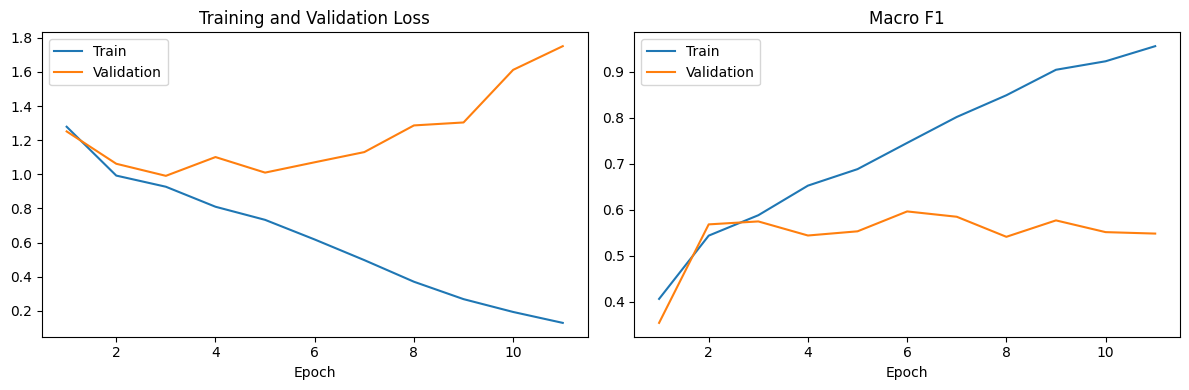


FINAL TEST METRICS
{
  "model": "vit_base_patch16_224",
  "num_classes": 5,
  "test_samples": 460,
  "accuracy": 0.532608695652174,
  "balanced_accuracy": 0.5374843911964234,
  "macro_f1": 0.5330432163299752,
  "weighted_f1": 0.5310070583940613,
  "macro_ovr_auroc": 0.830226223352782,
  "best_validation_macro_f1": 0.5962325411176901
}

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           No DR       0.49      0.52      0.51        82
            Mild       0.60      0.44      0.51       112
        Moderate       0.32      0.33      0.32        86
          Severe       0.52      0.63      0.57        97
Proliferative DR       0.75      0.77      0.76        83

        accuracy                           0.53       460
       macro avg       0.54      0.54      0.53       460
    weighted avg       0.54      0.53      0.53       460



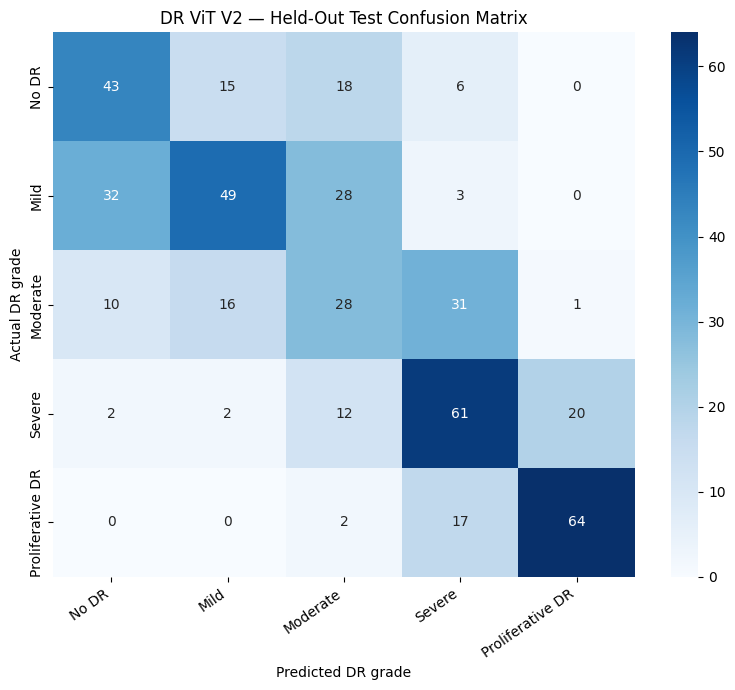


Saved outputs to: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/vit_v2
Best checkpoint: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/vit_v2/dr_vit_v2_best.pth
DR ViT V2 experiment complete.


In [9]:
# ============================================================
# DR V2 — Vision Transformer (ViT-B/16) [CORRECTED FOR CSV SPLITS]
# Five-class Diabetic Retinopathy Classification
# ============================================================

!pip -q install timm scikit-learn seaborn

import os
import json
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import timm

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from google.colab import drive

# ------------------------------------------------------------
# 1. CONFIGURATION & CSV LOAD
# ------------------------------------------------------------

drive.mount("/content/drive")

SEED = 42

BASE = Path(
    "/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy"
)

OUTPUT_DIR = BASE / "outputs" / "vit_v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load CSV splits (matching Notebook 01 & 02)
train_df = pd.read_csv(OUTPUT_DIR.parent / "dr_train.csv")
val_df = pd.read_csv(OUTPUT_DIR.parent / "dr_val.csv")
test_df = pd.read_csv(OUTPUT_DIR.parent / "dr_test.csv")

MODEL_NAME = "vit_base_patch16_224"
IMAGE_SIZE = 224

NUM_CLASSES = 5
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 5

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Train samples:", len(train_df))
print("Val samples:", len(val_df))
print("Test samples:", len(test_df))

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 3. PREPROCESSING FUNCTION (V2 CLAHE + CROP)
# ------------------------------------------------------------

def preprocess_dr_v2(image_path, image_size=224):
    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        margin = int(0.03 * max(w, h))
        x1, y1 = max(0, x - margin), max(0, y - margin)
        x2, y2 = min(image.shape[1], x + w + margin), min(image.shape[0], y + h + margin)
        image = image[y1:y2, x1:x2]

    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    enhanced_l = clahe.apply(l_channel)
    enhanced_lab = cv2.merge((enhanced_l, a_channel, b_channel))
    image = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)

    image = Image.fromarray(image)
    image = ImageOps.pad(image, (image_size, image_size), method=Image.Resampling.LANCZOS, color=(0, 0, 0))
    return image

# ------------------------------------------------------------
# 4. IMAGE TRANSFORMS & DATASET CLASS
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class DRDatasetV2(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = preprocess_dr_v2(row["image_path"])
        label = int(row["classe"])
        if self.transform is not None:
            image = self.transform(image)
        return image, label

train_dataset = DRDatasetV2(train_df, train_transform)
val_dataset = DRDatasetV2(val_df, eval_transform)
test_dataset = DRDatasetV2(test_df, eval_transform)

# ------------------------------------------------------------
# 5. DATA LOADERS
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 6. CLASS WEIGHTS — TRAINING DATA ONLY
# ------------------------------------------------------------

train_labels = np.array(
    train_df["classe"].tolist(),
    dtype=np.int64
)

class_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES
)

if np.any(class_counts == 0):
    raise ValueError(
        "Every DR class must be represented in training."
    )

class_weights = (
    len(train_labels)
    / (NUM_CLASSES * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("Training class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())

# ------------------------------------------------------------
# 7. CREATE PRETRAINED VISION TRANSFORMER
# ------------------------------------------------------------

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# ============================================================
# 8. TRAINING AND VALIDATION
# ============================================================

def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )

    with context:
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            predictions = logits.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy().tolist())
            all_predictions.extend(predictions.cpu().numpy().tolist())

    epoch_loss = total_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)
    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_macro_f1


history = []
best_val_f1 = -1.0
best_state = None
epochs_without_improvement = 0

CHECKPOINT_PATH = OUTPUT_DIR / "dr_vit_v2_best.pth"

for epoch in range(EPOCHS):
    train_loss, train_acc, train_f1 = run_epoch(train_loader, training=True)
    val_loss, val_acc, val_f1 = run_epoch(val_loader, training=False)

    scheduler.step()

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss={train_loss:.4f} | "
        f"Train F1={train_f1:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Val F1={val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, CHECKPOINT_PATH)
        epochs_without_improvement = 0
        print("  Saved new best checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# ------------------------------------------------------------
# 9. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "dr_vit_v2_training_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_macro_f1"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], label="Validation")
axes[1].set_title("Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dr_vit_v2_training_curves.png", dpi=200)
plt.show()

# ------------------------------------------------------------
# 10. LOAD BEST VALIDATION CHECKPOINT
# ------------------------------------------------------------

model.load_state_dict(
    torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
)
model.eval()

# ------------------------------------------------------------
# 11. FINAL HELD-OUT TEST EVALUATION
# ------------------------------------------------------------

y_true = []
y_pred = []
y_prob = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        logits = model(images)
        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(probabilities.cpu().numpy().tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

test_accuracy = accuracy_score(y_true, y_pred)
test_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)), average="weighted", zero_division=0)

try:
    test_auroc = roc_auc_score(y_true, y_prob, labels=list(range(NUM_CLASSES)), multi_class="ovr", average="macro")
except ValueError:
    test_auroc = None

metrics = {
    "model": MODEL_NAME,
    "num_classes": NUM_CLASSES,
    "test_samples": int(len(y_true)),
    "accuracy": float(test_accuracy),
    "balanced_accuracy": float(test_balanced_accuracy),
    "macro_f1": float(test_macro_f1),
    "weighted_f1": float(test_weighted_f1),
    "macro_ovr_auroc": float(test_auroc) if test_auroc is not None else None,
    "best_validation_macro_f1": float(best_val_f1)
}

with open(OUTPUT_DIR / "dr_vit_v2_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("\nFINAL TEST METRICS")
print(json.dumps(metrics, indent=2))

report = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, zero_division=0)
print("\nCLASSIFICATION REPORT")
print(report)

with open(OUTPUT_DIR / "dr_vit_v2_classification_report.txt", "w") as f:
    f.write(report)

# ------------------------------------------------------------
# 12. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted DR grade")
plt.ylabel("Actual DR grade")
plt.title("DR ViT V2 — Held-Out Test Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dr_vit_v2_confusion_matrix.png", dpi=200)
plt.show()

# ------------------------------------------------------------
# 13. SAVE INDIVIDUAL TEST PREDICTIONS (FIXED FOR CSV DATAFRAME)
# ------------------------------------------------------------

predictions_df = pd.DataFrame({
    "image_path": test_df["image_path"].tolist(),
    "true_grade": y_true,
    "predicted_grade": y_pred
})

for class_index in range(NUM_CLASSES):
    predictions_df[f"score_grade_{class_index}"] = y_prob[:, class_index]

predictions_df.to_csv(OUTPUT_DIR / "dr_vit_v2_test_predictions.csv", index=False)

# ------------------------------------------------------------
# 14. SAVE DEPLOYMENT CONFIG
# ------------------------------------------------------------

deployment_config = {
    "model_name": MODEL_NAME,
    "checkpoint": "models/dr/dr_vit_v2_best.pth",
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "image_normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "score_type": "uncalibrated_softmax",
    "disclaimer": "Research prototype only. Not a clinical diagnosis."
}

with open(OUTPUT_DIR / "dr_vit_v2_deployment_config.json", "w") as f:
    json.dump(deployment_config, f, indent=2)

print("\nSaved outputs to:", OUTPUT_DIR)
print("Best checkpoint:", CHECKPOINT_PATH)
print("DR ViT V2 experiment complete.")

In [10]:
# ============================================================
# DR MODEL COMPARISON: DenseNet-121 vs. ViT-B/16 (Held-Out Test Set)
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from pathlib import Path
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import densenet121
import timm
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import cv2
from PIL import Image, ImageOps

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BASE = Path("/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy")
OUTPUT_DIR = BASE / "outputs"
V2_DIR = OUTPUT_DIR / "v2"
VIT_DIR = OUTPUT_DIR / "vit_v2"
MODEL_DIR = V2_DIR / "models"

# 1. Load Test Metadata & Preprocessing
test_df = pd.read_csv(OUTPUT_DIR / "dr_test.csv")

def preprocess_dr_v2(image_path, image_size=224):
    image = Image.open(image_path).convert("RGB")
    image = np.array(image)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        margin = int(0.03 * max(w, h))
        x1, y1 = max(0, x - margin), max(0, y - margin)
        x2, y2 = min(image.shape[1], x + w + margin), min(image.shape[0], y + h + margin)
        image = image[y1:y2, x1:x2]
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    enhanced_l = clahe.apply(l_channel)
    enhanced_lab = cv2.merge((enhanced_l, a_channel, b_channel))
    image = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)
    image = Image.fromarray(image)
    image = ImageOps.pad(image, (image_size, image_size), method=Image.Resampling.LANCZOS, color=(0, 0, 0))
    return image

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DRTestDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = preprocess_dr_v2(row["image_path"])
        label = int(row["classe"])
        if self.transform:
            img = self.transform(img)
        return img, label

test_loader = DataLoader(DRTestDataset(test_df, eval_transform), batch_size=16, shuffle=False)
y_true = np.array([lbl for _, lbl in test_loader.dataset])
y_onehot = np.eye(5)[y_true]

# 2. Evaluation Helper Function
def evaluate_model(model, loader):
    model.eval()
    preds, probs_list = [], []
    with torch.inference_mode():
        for imgs, _ in loader:
            imgs = imgs.to(DEVICE)
            logits = model(imgs)
            probs = torch.softmax(logits.float(), dim=1)
            preds.extend(probs.argmax(dim=1).cpu().numpy())
            probs_list.extend(probs.cpu().numpy())
    return np.array(preds), np.array(probs_list)

results = []

# --- Evaluate DenseNet-121 ---
print("Evaluating DenseNet-121...")
densenet = densenet121(weights=None)
densenet.classifier = nn.Linear(densenet.classifier.in_features, 5)
densenet.load_state_dict(torch.load(MODEL_DIR / "dr_v2_densenet121_best.pth", map_location=DEVICE, weights_only=True))
densenet = densenet.to(DEVICE)

dn_preds, dn_probs = evaluate_model(densenet, test_loader)
dn_onehot = np.eye(5)[y_true]

results.append({
    "Architecture": "DenseNet-121 (CNN)",
    "Accuracy": round(accuracy_score(y_true, dn_preds), 4),
    "Balanced Acc": round(balanced_accuracy_score(y_true, dn_preds), 4),
    "Macro Precision": round(precision_score(y_true, dn_preds, average="macro", zero_division=0), 4),
    "Macro Recall": round(recall_score(y_true, dn_preds, average="macro", zero_division=0), 4),
    "Macro F1": round(f1_score(y_true, dn_preds, average="macro", zero_division=0), 4),
    "Macro OvR AUROC": round(roc_auc_score(y_true, dn_probs, multi_class="ovr", average="macro", labels=[0,1,2,3,4]), 4),
    "Multiclass Brier": round(np.mean(np.sum((dn_probs - dn_onehot) ** 2, axis=1)), 4)
})

# --- Evaluate ViT-B/16 ---
print("Evaluating ViT-B/16...")
vit = timm.create_model("vit_base_patch16_224", pretrained=False, num_classes=5)
vit.load_state_dict(torch.load(VIT_DIR / "dr_vit_v2_best.pth", map_location=DEVICE, weights_only=True))
vit = vit.to(DEVICE)

vit_preds, vit_probs = evaluate_model(vit, test_loader)
vit_onehot = np.eye(5)[y_true]

results.append({
    "Architecture": "ViT-B/16 (Transformer)",
    "Accuracy": round(accuracy_score(y_true, vit_preds), 4),
    "Balanced Acc": round(balanced_accuracy_score(y_true, vit_preds), 4),
    "Macro Precision": round(precision_score(y_true, vit_preds, average="macro", zero_division=0), 4),
    "Macro Recall": round(recall_score(y_true, vit_preds, average="macro", zero_division=0), 4),
    "Macro F1": round(f1_score(y_true, vit_preds, average="macro", zero_division=0), 4),
    "Macro OvR AUROC": round(roc_auc_score(y_true, vit_probs, multi_class="ovr", average="macro", labels=[0,1,2,3,4]), 4),
    "Multiclass Brier": round(np.mean(np.sum((vit_probs - vit_onehot) ** 2, axis=1)), 4)
})

# 3. Display and Save Comparison Table
comparison_df = pd.DataFrame(results)
print("\n" + "="*80)
print("DIABETIC RETINOPATHY — ARCHITECTURE COMPARISON (HELD-OUT TEST SET, n=460)")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

comparison_df.to_csv(OUTPUT_DIR / "dr_model_comparison_test.csv", index=False)
print(f"\nSaved comparison table to: {OUTPUT_DIR / 'dr_model_comparison_test.csv'}")

Evaluating DenseNet-121...
Evaluating ViT-B/16...

DIABETIC RETINOPATHY — ARCHITECTURE COMPARISON (HELD-OUT TEST SET, n=460)
          Architecture  Accuracy  Balanced Acc  Macro Precision  Macro Recall  Macro F1  Macro OvR AUROC  Multiclass Brier
    DenseNet-121 (CNN)    0.5174        0.5172           0.5136        0.5172    0.5128           0.8521            0.6082
ViT-B/16 (Transformer)    0.5326        0.5375           0.5360        0.5375    0.5330           0.8302            0.6486

Saved comparison table to: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/dr_model_comparison_test.csv
